# Landmark Extraction For Unified Multi-Class ASL Clips

This notebook builds its dataset from the generated `videos/` folder and `videos/preprocess_index.json`.
It predicts the canonical target signs listed below. Dataset source and variant labels are preserved as metadata only.

MediaPipe Holistic extracts pose, face, and hand landmarks, resamples every clip to 30 frames, and keeps the full 1629-feature representation. Face feature selection is intentionally deferred to later experiments.


In [1]:
# Run this only if MediaPipe is not installed in your environment.
# %pip install mediapipe opencv-python pandas numpy matplotlib

In [2]:
from pathlib import Path
import json
import random
import pickle
from collections import Counter, defaultdict

import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print


VIDEO_DIR = Path('videos')
PREPROCESS_INDEX = VIDEO_DIR / 'preprocess_index.json'
OUTPUT_DIR = Path('landmarks')
OUTPUT_DIR.mkdir(exist_ok=True)

SEED = 42
TRAIN_SIZE = 0.70
VAL_SIZE = 0.15
TEST_SIZE = 0.15
SEQUENCE_LENGTH = 30
EXPORT_SPLIT_CSV = True
TARGET_SIGNS = (
    'again',
    'bad',
    'bathroom',
    'book',
    'bye',
    "don't know",
    "don't like",
    "don't understand",
    "don't want",
    'drink',
    'eat',
    'family',
    'father',
    'finish',
    'friend',
    'go',
    'good',
    'happy',
    'have',
    'he',
    'hello',
    'help',
    'home',
    'know',
    'like',
    'me',
    'more',
    'mother',
    'name',
    'need',
    'no',
    'not',
    'now',
    'play',
    'please',
    'sad',
    'same',
    'school',
    'sorry',
    'sit',
    'stop',
    'thank you',
    'they',
    'think',
    'tired',
    'understand',
    'want',
    'water',
    'we',
    'what',
    'which',
    'who',
    'why',
    'work',
    'yes',
    'you',
)
USABLE_PREPROCESS_STATUSES = {'created', 'copied', 'skipped_existing'}

random.seed(SEED)
np.random.seed(SEED)

print(f'Video directory: {VIDEO_DIR.resolve()}')
print(f'Preprocess index: {PREPROCESS_INDEX.resolve()}')


Video directory: D:\Computerpreter\05272026 (third new)\videos
Preprocess index: D:\Computerpreter\05272026 (third new)\videos\preprocess_index.json


In [3]:
def normalize_label(value):
    label = str(value).strip().lower()
    if label not in TARGET_SIGNS:
        raise ValueError(f'Unexpected target sign {value!r}; expected one of {TARGET_SIGNS}')
    return label


def source_group_key(record, video_path):
    for key in ('url', 'source_path'):
        value = record.get(key)
        if value:
            return str(value)
    return str(video_path)


def load_available_samples(index_path=PREPROCESS_INDEX, video_dir=VIDEO_DIR):
    with open(index_path, 'r', encoding='utf-8') as f:
        records = json.load(f)

    samples = []
    skipped_status = Counter()
    missing_files = []
    bad_labels = []

    for record_idx, record in enumerate(records):
        status = record.get('status')
        if status not in USABLE_PREPROCESS_STATUSES:
            skipped_status[status] += 1
            continue

        raw_output_path = Path(record.get('output_path', ''))
        video_path = raw_output_path
        if not video_path.is_absolute():
            video_path = video_dir.parent / video_path
        if not video_path.exists() and (video_dir / raw_output_path.name).exists():
            video_path = video_dir / raw_output_path.name

        if not video_path.exists():
            missing_files.append(str(raw_output_path))
            continue

        try:
            label = normalize_label(record.get('target_sign'))
        except ValueError:
            bad_labels.append(record.get('target_sign'))
            continue

        samples.append({
            'record_index': record_idx,
            'filename': video_path.name,
            'path': str(video_path),
            'label': label,
            'dataset': record.get('dataset'),
            'matched_sign': record.get('matched_sign'),
            'preprocess_status': status,
            'source_path': record.get('source_path'),
            'url': record.get('url'),
            'source_split': record.get('split'),
            'manifest_index': record.get('manifest_index'),
            'video_id': record.get('video_id'),
            'instance_id': record.get('instance_id'),
            'participant_id': record.get('participant_id'),
            'asl_lex_code': record.get('asl_lex_code'),
            'start_time': record.get('start_time'),
            'end_time': record.get('end_time'),
            'group_key': source_group_key(record, video_path),
        })

    samples_df = pd.DataFrame(samples).sort_values(['label', 'dataset', 'filename']).reset_index(drop=True)
    label_counts = samples_df['label'].value_counts().sort_index() if not samples_df.empty else pd.Series(dtype=int)

    print(f'Loaded {len(records)} preprocess records')
    print(f'Found {len(samples_df)} usable videos in {video_dir}/')
    print(f'Missing output files: {len(missing_files)}')
    print(f'Skipped by preprocess status: {dict(skipped_status)}')
    if bad_labels:
        print(f'Skipped unexpected labels: {Counter(bad_labels)}')

    display(label_counts.rename_axis('label').rename('count').reset_index())
    display(pd.crosstab(samples_df['label'], samples_df['dataset']) if not samples_df.empty else samples_df)
    return samples_df, missing_files


samples_df, missing_clips = load_available_samples()
samples_df.head()


Loaded 5975 preprocess records
Found 4185 usable videos in videos/
Missing output files: 0
Skipped by preprocess status: {'missing_raw': 1790}


,label,count
0,again,77
1,bad,61
2,bathroom,103
3,book,75
4,bye,53
5,don't know,31
6,don't like,62
7,don't understand,78
8,don't want,35
9,drink,103


dataset,ASL_Citizen,MS-ASL,WLASL
label,,,
again,29,37,11
bad,30,22,9
bathroom,62,28,13
book,31,37,7
bye,30,21,2
don't know,31,0,0
don't like,62,0,0
don't understand,61,13,4
don't want,31,0,4


,record_index,filename,path,label,dataset,matched_sign,preprocess_status,source_path,url,source_split,manifest_index,video_id,instance_id,participant_id,asl_lex_code,start_time,end_time,group_key
0,5692,aslcitizen_again_AGAIN_023787576451673953-AGAI...,D:\Computerpreter\05272026 (third new)\videos\...,again,ASL_Citizen,AGAIN,copied,D:\Computerpreter\ASL_Citizen\videos\023787576...,None,test,NaN,None,NaN,P49,J_02_013,NaN,NaN,D:\Computerpreter\ASL_Citizen\videos\023787576...
1,4658,aslcitizen_again_AGAIN_04209701709386082-AGAIN...,D:\Computerpreter\05272026 (third new)\videos\...,again,ASL_Citizen,AGAIN,copied,D:\Computerpreter\ASL_Citizen\videos\042097017...,None,train,NaN,None,NaN,P11,J_02_013,NaN,NaN,D:\Computerpreter\ASL_Citizen\videos\042097017...
2,5305,aslcitizen_again_AGAIN_06926356735568229-AGAIN...,D:\Computerpreter\05272026 (third new)\videos\...,again,ASL_Citizen,AGAIN,copied,D:\Computerpreter\ASL_Citizen\videos\069263567...,None,test,NaN,None,NaN,P6,J_02_013,NaN,NaN,D:\Computerpreter\ASL_Citizen\videos\069263567...
3,5523,aslcitizen_again_AGAIN_11794226320729084-AGAIN...,D:\Computerpreter\05272026 (third new)\videos\...,again,ASL_Citizen,AGAIN,copied,D:\Computerpreter\ASL_Citizen\videos\117942263...,None,test,NaN,None,NaN,P18,J_02_013,NaN,NaN,D:\Computerpreter\ASL_Citizen\videos\117942263...
4,4323,aslcitizen_again_AGAIN_15930574135298836-AGAIN...,D:\Computerpreter\05272026 (third new)\videos\...,again,ASL_Citizen,AGAIN,copied,D:\Computerpreter\ASL_Citizen\videos\159305741...,None,train,NaN,None,NaN,P27,J_02_013,NaN,NaN,D:\Computerpreter\ASL_Citizen\videos\159305741...


In [4]:
def grouped_stratified_split(
    df,
    label_col='label',
    group_col='group_key',
    train_size=TRAIN_SIZE,
    val_size=VAL_SIZE,
    test_size=TEST_SIZE,
    seed=SEED,
):
    if df.empty:
        raise ValueError('No usable videos found. Run preprocess.py first and check videos/preprocess_index.json.')

    total_ratio = train_size + val_size + test_size
    if not np.isclose(total_ratio, 1.0):
        raise ValueError(f'Split ratios must sum to 1.0, got {total_ratio}')

    rng = random.Random(seed)
    label_to_id = {label: idx for idx, label in enumerate(sorted(TARGET_SIGNS))}

    group_rows = []
    for group_key, group in df.groupby(group_col, sort=True):
        label_counts = group[label_col].value_counts()
        group_label = label_counts.sort_values(ascending=False).index[0]
        group_rows.append({
            'group_key': group_key,
            'group_label': group_label,
            'size': len(group),
            'indices': list(group.index),
        })

    target_counts = {
        'train': df[label_col].value_counts().mul(train_size),
        'val': df[label_col].value_counts().mul(val_size),
        'test': df[label_col].value_counts().mul(test_size),
    }
    split_indices = {'train': [], 'val': [], 'test': []}
    split_label_counts = {name: Counter() for name in split_indices}

    grouped_by_label = defaultdict(list)
    for group in group_rows:
        grouped_by_label[group['group_label']].append(group)

    for label in sorted(grouped_by_label):
        groups = grouped_by_label[label]
        rng.shuffle(groups)
        for group in sorted(groups, key=lambda item: item['size'], reverse=True):
            deficits = {}
            for split_name in ('train', 'val', 'test'):
                current = split_label_counts[split_name][label]
                target = target_counts[split_name].get(label, 0)
                deficits[split_name] = target - current

            split_name = max(deficits, key=lambda name: (deficits[name], -len(split_indices[name])))
            split_indices[split_name].extend(group['indices'])
            for row_idx in group['indices']:
                split_label_counts[split_name][df.loc[row_idx, label_col]] += 1

    split_dfs = {}
    for split_name, indices in split_indices.items():
        split_df = df.loc[indices].sample(frac=1, random_state=seed).reset_index(drop=True)
        split_df['label_id'] = split_df[label_col].map(label_to_id)
        split_df['split'] = split_name
        split_dfs[split_name] = split_df

    return split_dfs['train'], split_dfs['val'], split_dfs['test'], label_to_id


train_df, val_df, test_df, label_to_id = grouped_stratified_split(samples_df)

print('Label map:', label_to_id)
print(f'Train clips: {len(train_df)}')
print(f'Val clips: {len(val_df)}')
print(f'Test clips: {len(test_df)}')

display(pd.concat({
    'train': train_df.groupby('label').size(),
    'val': val_df.groupby('label').size(),
    'test': test_df.groupby('label').size(),
}, axis=1).fillna(0).astype(int))

if EXPORT_SPLIT_CSV:
    train_df.to_csv(OUTPUT_DIR / 'ASL_TRAIN_generated.csv', index=False)
    val_df.to_csv(OUTPUT_DIR / 'ASL_VAL_generated.csv', index=False)
    test_df.to_csv(OUTPUT_DIR / 'ASL_TEST_generated.csv', index=False)
    print(f'Wrote split CSVs to {OUTPUT_DIR}/')


Label map: {'again': 0, 'bad': 1, 'bathroom': 2, 'book': 3, 'bye': 4, "don't know": 5, "don't like": 6, "don't understand": 7, "don't want": 8, 'drink': 9, 'eat': 10, 'family': 11, 'father': 12, 'finish': 13, 'friend': 14, 'go': 15, 'good': 16, 'happy': 17, 'have': 18, 'he': 19, 'hello': 20, 'help': 21, 'home': 22, 'know': 23, 'like': 24, 'me': 25, 'more': 26, 'mother': 27, 'name': 28, 'need': 29, 'no': 30, 'not': 31, 'now': 32, 'play': 33, 'please': 34, 'sad': 35, 'same': 36, 'school': 37, 'sit': 38, 'sorry': 39, 'stop': 40, 'thank you': 41, 'they': 42, 'think': 43, 'tired': 44, 'understand': 45, 'want': 46, 'water': 47, 'we': 48, 'what': 49, 'which': 50, 'who': 51, 'why': 52, 'work': 53, 'yes': 54, 'you': 55}
Train clips: 3113
Val clips: 536
Test clips: 536


,train,val,test
label,,,
again,63,7,7
bad,51,5,5
bathroom,77,13,13
book,59,8,8
bye,41,6,6
don't know,22,5,4
don't like,44,9,9
don't understand,58,10,10
don't want,25,5,5


Wrote split CSVs to landmarks/


In [5]:
mp_holistic = mp.solutions.holistic

NUM_POSE = 33
NUM_FACE = 468
NUM_HAND = 21
FEATURE_DIMS = 3 * (NUM_POSE + NUM_FACE + 2 * NUM_HAND)
LEFT_SHOULDER = 11
RIGHT_SHOULDER = 12


def landmarks_to_array(landmarks, expected_count):
    arr = np.zeros((expected_count, 3), dtype=np.float32)
    if landmarks is None:
        return arr

    for i, landmark in enumerate(landmarks.landmark[:expected_count]):
        arr[i] = [landmark.x, landmark.y, landmark.z]
    return arr


def normalize_landmarks(pose, face, left_hand, right_hand):
    all_points = np.concatenate([pose, face, left_hand, right_hand], axis=0)
    detected_mask = np.any(all_points != 0, axis=1)

    left_shoulder = pose[LEFT_SHOULDER]
    right_shoulder = pose[RIGHT_SHOULDER]

    shoulders_detected = np.any(left_shoulder) and np.any(right_shoulder)
    if shoulders_detected:
        center = (left_shoulder + right_shoulder) / 2.0
        scale = np.linalg.norm(left_shoulder[:2] - right_shoulder[:2])
        if scale > 1e-6:
            all_points[detected_mask] = (all_points[detected_mask] - center) / scale

    return all_points.reshape(-1).astype(np.float32)


def resample_sequence(sequence, target_length=SEQUENCE_LENGTH):
    sequence = np.asarray(sequence, dtype=np.float32)

    if len(sequence) == 0:
        return np.zeros((target_length, FEATURE_DIMS), dtype=np.float32)

    if len(sequence) == target_length:
        return sequence

    if len(sequence) == 1:
        return np.repeat(sequence, target_length, axis=0)

    source_positions = np.linspace(0, len(sequence) - 1, num=len(sequence))
    target_positions = np.linspace(0, len(sequence) - 1, num=target_length)

    resampled = np.empty((target_length, sequence.shape[1]), dtype=np.float32)
    for feature_idx in range(sequence.shape[1]):
        resampled[:, feature_idx] = np.interp(target_positions, source_positions, sequence[:, feature_idx])

    return resampled


def extract_landmarks_from_video(video_path, sequence_length=SEQUENCE_LENGTH):
    frames = []
    cap = cv2.VideoCapture(str(video_path))

    with mp_holistic.Holistic(
        static_image_mode=False,
        model_complexity=1,
        smooth_landmarks=True,
        enable_segmentation=False,
        refine_face_landmarks=False,
    ) as holistic:
        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break

            image_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            image_rgb.flags.writeable = False
            results = holistic.process(image_rgb)

            pose = landmarks_to_array(results.pose_landmarks, NUM_POSE)
            face = landmarks_to_array(results.face_landmarks, NUM_FACE)
            left_hand = landmarks_to_array(results.left_hand_landmarks, NUM_HAND)
            right_hand = landmarks_to_array(results.right_hand_landmarks, NUM_HAND)

            frames.append(normalize_landmarks(pose, face, left_hand, right_hand))

    cap.release()
    return resample_sequence(frames, sequence_length)


In [6]:
def extract_split_landmarks(split_df, split_name):
    X = np.zeros((len(split_df), SEQUENCE_LENGTH, FEATURE_DIMS), dtype=np.float32)
    y = split_df['label_id'].to_numpy(dtype=np.int64)

    for row_idx, row in split_df.reset_index(drop=True).iterrows():
        X[row_idx] = extract_landmarks_from_video(row['path'])
        print(f'{split_name}: processed {row_idx + 1}/{len(split_df)} videos')

    print(f'{split_name}: processed {len(split_df)}/{len(split_df)} videos')
    return X, y


train_X, train_y = extract_split_landmarks(train_df, 'train')
val_X, val_y = extract_split_landmarks(val_df, 'val')
test_X, test_y = extract_split_landmarks(test_df, 'test')

print('train_X:', train_X.shape, 'train_y:', train_y.shape)
print('val_X:', val_X.shape, 'val_y:', val_y.shape)
print('test_X:', test_X.shape, 'test_y:', test_y.shape)


train: processed 1/3113 videos
train: processed 2/3113 videos
train: processed 3/3113 videos
train: processed 4/3113 videos
train: processed 5/3113 videos
train: processed 6/3113 videos
train: processed 7/3113 videos
train: processed 8/3113 videos
train: processed 9/3113 videos
train: processed 10/3113 videos
train: processed 11/3113 videos
train: processed 12/3113 videos
train: processed 13/3113 videos
train: processed 14/3113 videos
train: processed 15/3113 videos
train: processed 16/3113 videos
train: processed 17/3113 videos
train: processed 18/3113 videos
train: processed 19/3113 videos
train: processed 20/3113 videos
train: processed 21/3113 videos
train: processed 22/3113 videos
train: processed 23/3113 videos
train: processed 24/3113 videos
train: processed 25/3113 videos
train: processed 26/3113 videos
train: processed 27/3113 videos
train: processed 28/3113 videos
train: processed 29/3113 videos
train: processed 30/3113 videos
train: processed 31/3113 videos
train: processed 

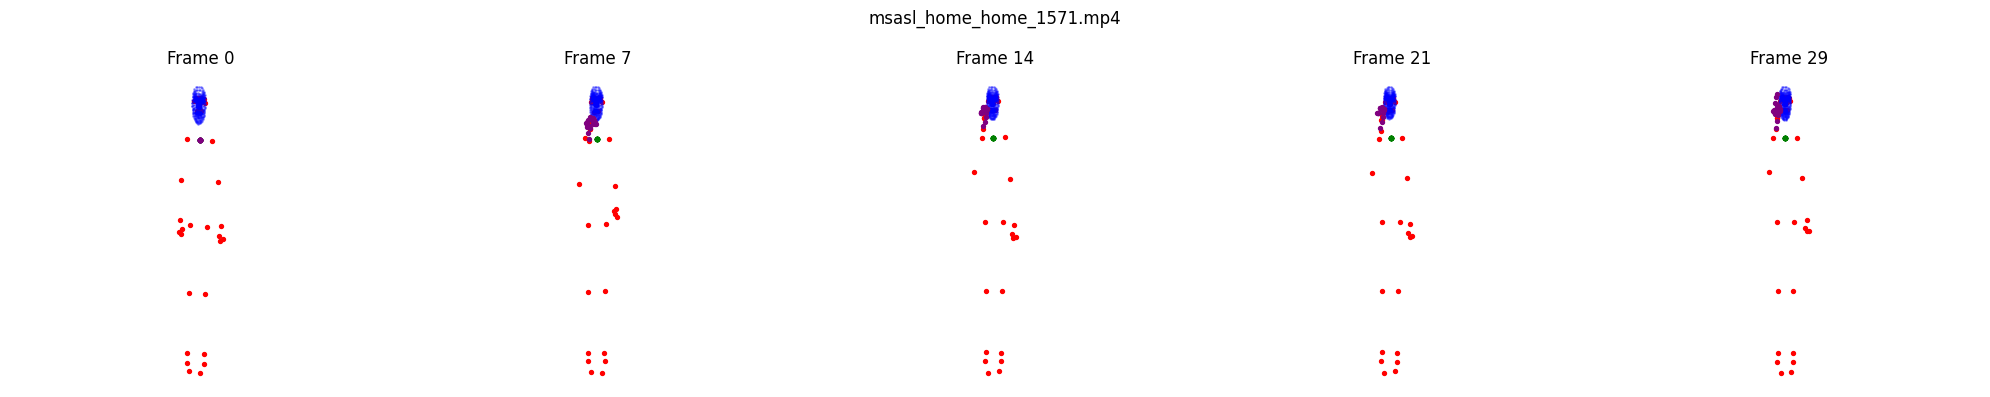

In [7]:
def visualize_landmarks_sequence(sequence, title='', num_frames=5):
    frame_indices = np.linspace(0, len(sequence) - 1, num_frames, dtype=int)
    fig, axes = plt.subplots(1, num_frames, figsize=(4 * num_frames, 4))
    if num_frames == 1:
        axes = [axes]

    for ax, frame_idx in zip(axes, frame_indices):
        frame = sequence[frame_idx]
        points = frame.reshape(-1, 3)

        pose = points[:NUM_POSE]
        face = points[NUM_POSE:NUM_POSE + NUM_FACE]
        left_hand = points[NUM_POSE + NUM_FACE:NUM_POSE + NUM_FACE + NUM_HAND]
        right_hand = points[NUM_POSE + NUM_FACE + NUM_HAND:]

        ax.scatter(pose[:, 0], -pose[:, 1], c='red', s=8, label='pose')
        ax.scatter(face[:, 0], -face[:, 1], c='blue', s=1, alpha=0.35, label='face')
        ax.scatter(left_hand[:, 0], -left_hand[:, 1], c='green', s=8, label='left hand')
        ax.scatter(right_hand[:, 0], -right_hand[:, 1], c='purple', s=8, label='right hand')
        ax.set_title(f'Frame {frame_idx}')
        ax.axis('equal')
        ax.axis('off')

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


sample_idx = 0
visualize_landmarks_sequence(train_X[sample_idx], title=train_df.iloc[sample_idx]['filename'])


In [8]:
if set(label_to_id) != set(TARGET_SIGNS):
    raise ValueError(f'label_to_id must contain exactly {TARGET_SIGNS}, got {label_to_id}')

with open(OUTPUT_DIR / 'label_to_id.pkl', 'wb') as f:
    pickle.dump(label_to_id, f)

with open(OUTPUT_DIR / 'train_landmarks.pkl', 'wb') as f:
    pickle.dump({'X': train_X, 'y': train_y, 'metadata': train_df, 'label_to_id': label_to_id}, f)

with open(OUTPUT_DIR / 'val_landmarks.pkl', 'wb') as f:
    pickle.dump({'X': val_X, 'y': val_y, 'metadata': val_df, 'label_to_id': label_to_id}, f)

with open(OUTPUT_DIR / 'test_landmarks.pkl', 'wb') as f:
    pickle.dump({'X': test_X, 'y': test_y, 'metadata': test_df, 'label_to_id': label_to_id}, f)

np.save(OUTPUT_DIR / 'train_X.npy', train_X)
np.save(OUTPUT_DIR / 'train_y.npy', train_y)
np.save(OUTPUT_DIR / 'val_X.npy', val_X)
np.save(OUTPUT_DIR / 'val_y.npy', val_y)
np.save(OUTPUT_DIR / 'test_X.npy', test_X)
np.save(OUTPUT_DIR / 'test_y.npy', test_y)

print(f'Saved landmark arrays and metadata to {OUTPUT_DIR.resolve()}')


Saved landmark arrays and metadata to D:\Computerpreter\05272026 (third new)\landmarks
